## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)  # logits (softmax removed: CrossEntropyLoss expects logits; verification is on logits)
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 0.593
Epoch 2/15, Loss: 0.297
Epoch 3/15, Loss: 0.248
Epoch 4/15, Loss: 0.215
Epoch 5/15, Loss: 0.190
Epoch 6/15, Loss: 0.170
Epoch 7/15, Loss: 0.155
Epoch 8/15, Loss: 0.142
Epoch 9/15, Loss: 0.130
Epoch 10/15, Loss: 0.121
Epoch 11/15, Loss: 0.113
Epoch 12/15, Loss: 0.106
Epoch 13/15, Loss: 0.099
Epoch 14/15, Loss: 0.093
Epoch 15/15, Loss: 0.088
Accuracy on images: 97.06


### Write the interval analysis for the simple model

eps=0.01 --- verified accuracy, 63.47%
eps=0.02 --- verified accuracy, 8.48%
eps=0.03 --- verified accuracy, 0.74%
eps=0.04 --- verified accuracy, 0.04%
eps=0.05 --- verified accuracy, 0.00%
eps=0.06 --- verified accuracy, 0.00%
eps=0.07 --- verified accuracy, 0.00%
eps=0.08 --- verified accuracy, 0.00%
eps=0.09 --- verified accuracy, 0.00%
eps=0.10 --- verified accuracy, 0.00%


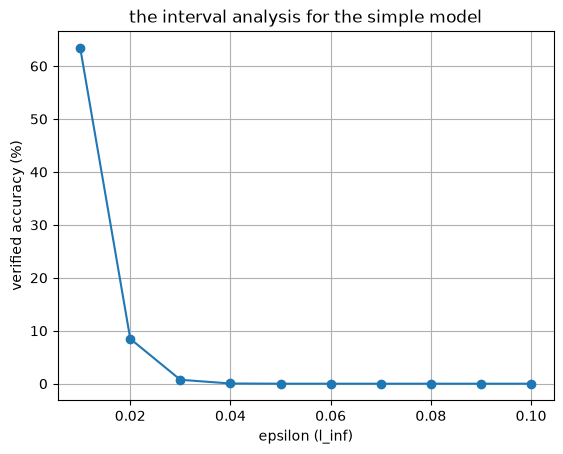

In [4]:
def interval_linear(lo, hi, W, b):
    Wp, Wn = W.clamp(min=0), W.clamp(max=0)
    return lo @ Wp.T + hi @ Wn.T + b, hi @ Wp.T + lo @ Wn.T + b

@torch.no_grad()
def verify_batch(model, x, y, eps):
    # check if image is proved robust in the l_inf epsilon radius
    net = model[1]
    x = x.view(-1, 784)
    n = x.shape[0]
    # input box have domain [0,1]
    lo, hi = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    # normalize layer 
    lo, hi = (lo - 0.1307) / 0.3081, (hi - 0.1307) / 0.3081
    # fc + ReLU
    lo, hi = interval_linear(lo, hi, net.fc.weight, net.fc.bias)
    lo, hi = F.relu(lo), F.relu(hi)
    # extra output layer j != y
    I = torch.eye(10, device=x.device)
    C = I[y].unsqueeze(1) - I.unsqueeze(0) # n x 10 x 10 size
    W = C @ net.fc2.weight # n x 10 x 200 size
    b = C @ net.fc2.bias # n x 10
    Wp, Wn = W.clamp(min=0), W.clamp(max=0)
    out_lo = (Wp @ lo.unsqueeze(-1) + Wn @ hi.unsqueeze(-1)).squeeze(-1) + b
    out_lo[torch.arange(n), y] = float('inf') # don't consider j == y
    return out_lo.min(dim=1).values >= 0

model.eval()
# sized evenly between 0.01 and 0.1 (inclusive)
epsilons = np.linspace(0.01, 0.1, 10)
results = []
for eps in epsilons:
    ver = total = 0
    for images, labels in test_loader:
        ver += verify_batch(model, images.to(device), labels.to(device), eps).sum().item()
        total += labels.size(0)
    results.append(100 * ver / total)
    print(f'eps={eps:.2f} --- verified accuracy, {results[-1]:.2f}%')

plt.plot(epsilons, results, marker='o')
plt.xlabel('epsilon (l_inf)'); plt.ylabel('verified accuracy (%)'); plt.grid(True)
plt.title('the interval analysis for the simple model')
plt.show()